# 07C — End-to-end threshold recalibration

## Objective

Notebook 07 calibrated each species threshold from the one-vs-all score rule

\[
LLR_k(X) \ge \theta_k,
\]

but the deployed detector does **not** declare species `k` from that condition alone.

The actual detector first chooses the winning GMM:

\[
\hat{k} = \arg\max_j s_j(X),
\]

and only then verifies that winning hypothesis:

\[
\text{detect }k
\iff
(\hat{k}=k)
\land
(LLR_k(X)\ge\theta_k).
\]

Notebook 07B showed that this distinction matters strongly for `f02`. Several non-`f02` calls had high
`LLR_f02`, but their winning GMM was not `f02`, so they could never become deployed `f02` detections.
The original one-vs-all ROC therefore pushed the `f02` threshold much higher than necessary.

## What this notebook changes

- **No GMM is retrained.**
- **No feature representation changes.**
- **No TRAIN/CALIBRATION split changes.**
- The already frozen PLP-RASTA GMMs remain untouched.
- Only the threshold-selection rule is recalculated so that calibration matches the detector actually deployed.

## Threshold-selection rule

For every species `k`, evaluate the end-to-end detector decision

\[
(\hat{k}=k)\land(LLR_k\ge\theta_k).
\]

Among candidate thresholds satisfying

\[
FPR_k \le 0.05,
\]

choose:

1. maximum recall / TPR;
2. if tied, the **largest threshold**.

This preserves the low-false-positive philosophy used previously while removing false constraints from
calls that could never be classified as `k` in the first place.

## Safety rule

This notebook writes **candidate** thresholds to a new output location.

It does **not** overwrite:

`models/gmm_robust_final/thresholds.json`

until the new results have been reviewed.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 220)
pd.set_option("display.max_columns", 120)

CWD = Path.cwd().resolve()
REPO_ROOT = CWD.parent if CWD.name == "notebooks" else CWD

CALIBRATION_DIR = (
    REPO_ROOT
    / "data"
    / "processed"
    / "final_detector_calibration"
)

MODEL_DIR = (
    REPO_ROOT
    / "models"
    / "gmm_robust_final"
)

RESULTS_DIR = (
    CALIBRATION_DIR
    / "end_to_end_threshold_calibration"
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

SCORES_PATH = (
    CALIBRATION_DIR
    / "calibration_scores_and_llr.csv"
)

OLD_THRESHOLDS_TABLE_PATH = (
    CALIBRATION_DIR
    / "thresholds_and_roc_operating_points.csv"
)

OLD_THRESHOLDS_JSON_PATH = (
    MODEL_DIR
    / "thresholds.json"
)

METADATA_PATH = (
    MODEL_DIR
    / "detector_metadata.json"
)

for path in (
    SCORES_PATH,
    OLD_THRESHOLDS_TABLE_PATH,
    OLD_THRESHOLDS_JSON_PATH,
    METADATA_PATH,
):
    if not path.exists():
        raise FileNotFoundError(
            f"Missing required notebook-07 output: {path}"
        )

print("Calibration data :", CALIBRATION_DIR)
print("Frozen detector  :", MODEL_DIR)
print("07C outputs      :", RESULTS_DIR)

Calibration data : C:\Users\sofia\Projects\PUCE\frog-presence-replication\data\processed\final_detector_calibration
Frozen detector  : C:\Users\sofia\Projects\PUCE\frog-presence-replication\models\gmm_robust_final
07C outputs      : C:\Users\sofia\Projects\PUCE\frog-presence-replication\data\processed\final_detector_calibration\end_to_end_threshold_calibration


## 2. Load the frozen detector scores

These are the calibration scores produced by the same GMM objects already serialized by notebook 07.
Nothing is rescored or retrained here.

In [2]:
scores = pd.read_csv(
    SCORES_PATH
)

old_threshold_table = pd.read_csv(
    OLD_THRESHOLDS_TABLE_PATH
)

with open(
    OLD_THRESHOLDS_JSON_PATH,
    "r",
    encoding="utf-8",
) as f:
    OLD_THRESHOLDS = json.load(f)

with open(
    METADATA_PATH,
    "r",
    encoding="utf-8",
) as f:
    DETECTOR_METADATA = json.load(f)

USABLE_CODES = tuple(
    DETECTOR_METADATA[
        "classes"
    ]
)

FEATURE_NAME = str(
    DETECTOR_METADATA[
        "feature"
    ]
)

N_COMPONENTS = int(
    DETECTOR_METADATA[
        "n_components"
    ]
)

TARGET_MAX_FPR = float(
    DETECTOR_METADATA.get(
        "calibration_target_max_FPR",
        0.05,
    )
)

required_columns = {
    "call_id",
    "true_code",
    "hypothesis",
}

for code in USABLE_CODES:
    required_columns.add(
        f"llr_{code}"
    )

missing = (
    required_columns
    - set(scores.columns)
)

if missing:
    raise ValueError(
        f"Missing score columns: {sorted(missing)}"
    )

print("Feature          :", FEATURE_NAME)
print("GMM components   :", N_COMPONENTS)
print("Classes          :", USABLE_CODES)
print("Calibration calls:", len(scores))
print("Target max FPR   :", TARGET_MAX_FPR)

Feature          : 20_PLP_RASTA
GMM components   : 4
Classes          : ('f01', 'f02', 'f03', 'f04', 'f05', 'f06', 'f07', 'f08', 'f10')
Calibration calls: 382
Target max FPR   : 0.05


## 3. Generic end-to-end metrics for one species

For species `k`, a detector-positive event requires both:

- `hypothesis == k`;
- `LLR_k >= threshold`.

This function is the core of the corrected calibration.

In [3]:
def end_to_end_metrics(
    code,
    threshold,
):
    y_true = (
        scores[
            "true_code"
        ] == code
    ).to_numpy()

    hypothesis_is_code = (
        scores[
            "hypothesis"
        ] == code
    ).to_numpy()

    llr = (
        scores[
            f"llr_{code}"
        ]
        .to_numpy()
    )

    y_pred = (
        hypothesis_is_code
        & (
            llr >= threshold
        )
    )

    TP = int(
        np.sum(
            y_true
            & y_pred
        )
    )

    FN = int(
        np.sum(
            y_true
            & ~y_pred
        )
    )

    FP = int(
        np.sum(
            ~y_true
            & y_pred
        )
    )

    TN = int(
        np.sum(
            ~y_true
            & ~y_pred
        )
    )

    recall = (
        TP / (TP + FN)
        if (TP + FN)
        else np.nan
    )

    precision = (
        TP / (TP + FP)
        if (TP + FP)
        else np.nan
    )

    fpr = (
        FP / (FP + TN)
        if (FP + TN)
        else np.nan
    )

    specificity = (
        TN / (TN + FP)
        if (TN + FP)
        else np.nan
    )

    f1 = (
        2
        * precision
        * recall
        / (
            precision
            + recall
        )
        if (
            np.isfinite(
                precision
            )
            and np.isfinite(
                recall
            )
            and (
                precision
                + recall
            ) > 0
        )
        else np.nan
    )

    return {
        "code":
            code,
        "threshold":
            float(
                threshold
            ),
        "TP":
            TP,
        "FN":
            FN,
        "FP":
            FP,
        "TN":
            TN,
        "recall":
            recall,
        "TPR":
            recall,
        "precision":
            precision,
        "F1":
            f1,
        "FPR":
            fpr,
        "specificity":
            specificity,
        "n_positive":
            int(
                y_true.sum()
            ),
        "n_negative":
            int(
                len(y_true)
                - y_true.sum()
            ),
        "n_hypothesis_calls":
            int(
                hypothesis_is_code.sum()
            ),
    }

## 4. Build the complete threshold sweep for every class

Threshold candidates are taken from observed `LLR_k` values **only where `k` is the winning
hypothesis**, plus sentinel values above and below the observed range.

That is sufficient because the deployed class decision can change only on those calls.

In [4]:
sweep_blocks = []

for code in USABLE_CODES:

    winner_mask = (
        scores[
            "hypothesis"
        ] == code
    )

    winner_llr = (
        scores.loc[
            winner_mask,
            f"llr_{code}",
        ]
        .to_numpy()
    )

    if len(
        winner_llr
    ) == 0:
        raise RuntimeError(
            f"No calibration call has {code} as winning hypothesis."
        )

    candidate_thresholds = np.unique(
        np.concatenate([
            winner_llr,
            np.array([
                winner_llr.min() - 1e-9,
                winner_llr.max() + 1e-9,
                float(
                    OLD_THRESHOLDS[
                        code
                    ]
                ),
            ]),
        ])
    )

    rows = []

    for threshold in candidate_thresholds:

        rows.append(
            end_to_end_metrics(
                code=code,
                threshold=float(
                    threshold
                ),
            )
        )

    sweep = (
        pd.DataFrame(
            rows
        )
        .sort_values(
            "threshold",
            ascending=False,
        )
        .reset_index(drop=True)
    )

    sweep_blocks.append(
        sweep
    )

threshold_sweep = pd.concat(
    sweep_blocks,
    ignore_index=True,
)

print(
    "Threshold operating points evaluated:",
    len(
        threshold_sweep
    ),
)

Threshold operating points evaluated: 401


## 5. Select one corrected threshold per species

Selection rule:

- keep `FPR <= 5%`;
- maximize recall;
- if recall ties, choose the largest threshold.

The largest-threshold tie break is conservative: it preserves the same recall while maximizing margin
from rejected calls.

In [5]:
new_threshold_rows = []

for code in USABLE_CODES:

    sweep = (
        threshold_sweep[
            threshold_sweep[
                "code"
            ] == code
        ]
        .copy()
    )

    feasible = (
        sweep[
            sweep[
                "FPR"
            ]
            <= TARGET_MAX_FPR
            + 1e-12
        ]
        .copy()
    )

    if feasible.empty:
        raise RuntimeError(
            f"No end-to-end operating point satisfies "
            f"FPR <= {TARGET_MAX_FPR} for {code}."
        )

    best_recall = float(
        feasible[
            "recall"
        ].max()
    )

    tied = (
        feasible[
            np.isclose(
                feasible[
                    "recall"
                ],
                best_recall,
            )
        ]
        .sort_values(
            "threshold",
            ascending=False,
        )
    )

    selected = (
        tied.iloc[0]
    )

    new_threshold_rows.append(
        selected.to_dict()
    )

new_threshold_table = (
    pd.DataFrame(
        new_threshold_rows
    )
    .sort_values(
        "code"
    )
    .reset_index(drop=True)
)

NEW_THRESHOLDS = {
    row.code: float(
        row.threshold
    )
    for row
    in new_threshold_table.itertuples(
        index=False
    )
}

display(
    new_threshold_table[
        [
            "code",
            "threshold",
            "TP",
            "FN",
            "FP",
            "TN",
            "recall",
            "precision",
            "F1",
            "FPR",
            "specificity",
        ]
    ].round(4)
)

if (
    new_threshold_table[
        "FPR"
    ]
    > TARGET_MAX_FPR
    + 1e-12
).any():
    raise AssertionError(
        "Selected end-to-end threshold violates the FPR constraint."
    )

,code,threshold,TP,FN,FP,TN,recall,precision,F1,FPR,specificity
0,f01,8.0751,19,0,0,363,1.0000,1.0000,1.0000,0.0000,1.0000
1,f02,3.7012,22,2,3,355,0.9167,0.8800,0.8980,0.0084,0.9916
2,f03,6.9382,26,0,0,356,1.0000,1.0000,1.0000,0.0000,1.0000
3,f04,5.0647,46,1,0,335,0.9787,1.0000,0.9892,0.0000,1.0000
4,f05,5.5535,129,6,1,246,0.9556,0.9923,0.9736,0.0040,0.9960
5,f06,5.2310,13,0,0,369,1.0000,1.0000,1.0000,0.0000,1.0000
6,f07,5.7501,17,0,0,365,1.0000,1.0000,1.0000,0.0000,1.0000
7,f08,7.1894,25,0,0,357,1.0000,1.0000,1.0000,0.0000,1.0000
8,f10,9.0146,76,0,1,305,1.0000,0.9870,0.9935,0.0033,0.9967


## 6. Recompute the old thresholds using the same end-to-end metric

This gives a fair old-versus-new comparison. The old table from notebook 07 contained ROC-level
operating points based on the different one-vs-all thresholding rule.

In [6]:
old_end_to_end_rows = []

for code in USABLE_CODES:

    old_end_to_end_rows.append(
        end_to_end_metrics(
            code=code,
            threshold=float(
                OLD_THRESHOLDS[
                    code
                ]
            ),
        )
    )

old_end_to_end_table = (
    pd.DataFrame(
        old_end_to_end_rows
    )
    .sort_values(
        "code"
    )
    .reset_index(drop=True)
)

display(
    old_end_to_end_table[
        [
            "code",
            "threshold",
            "TP",
            "FN",
            "FP",
            "recall",
            "precision",
            "F1",
            "FPR",
        ]
    ].round(4)
)

,code,threshold,TP,FN,FP,recall,precision,F1,FPR
0,f01,8.0751,19,0,0,1.0000,1.0000,1.0000,0.0000
1,f02,8.5813,3,21,2,0.1250,0.6000,0.2069,0.0056
2,f03,6.9382,26,0,0,1.0000,1.0000,1.0000,0.0000
3,f04,1.9181,46,1,0,0.9787,1.0000,0.9892,0.0000
4,f05,5.5535,129,6,1,0.9556,0.9923,0.9736,0.0040
5,f06,5.2310,13,0,0,1.0000,1.0000,1.0000,0.0000
6,f07,5.7501,17,0,0,1.0000,1.0000,1.0000,0.0000
7,f08,7.1894,25,0,0,1.0000,1.0000,1.0000,0.0000
8,f10,9.0146,76,0,1,1.0000,0.9870,0.9935,0.0033


## 7. Old versus corrected threshold comparison

In [8]:
comparison = (
    old_end_to_end_table[
        [
            "code",
            "threshold",
            "recall",
            "precision",
            "F1",
            "FPR",
            "TP",
            "FN",
            "FP",
        ]
    ]
    .rename(
        columns={
            "threshold":
                "old_threshold",
            "recall":
                "old_recall",
            "precision":
                "old_precision",
            "F1":
                "old_F1",
            "FPR":
                "old_FPR",
            "TP":
                "old_TP",
            "FN":
                "old_FN",
            "FP":
                "old_FP",
        }
    )
    .merge(
        new_threshold_table[
            [
                "code",
                "threshold",
                "recall",
                "precision",
                "F1",
                "FPR",
                "TP",
                "FN",
                "FP",
            ]
        ].rename(
            columns={
                "threshold":
                    "new_threshold",
                "recall":
                    "new_recall",
                "precision":
                    "new_precision",
                "F1":
                    "new_F1",
                "FPR":
                    "new_FPR",
                "TP":
                    "new_TP",
                "FN":
                    "new_FN",
                "FP":
                    "new_FP",
            }
        ),
        on="code",
        how="inner",
        validate="one_to_one",
    )
)

comparison[
    "threshold_change"
] = (
    comparison[
        "new_threshold"
    ]
    - comparison[
        "old_threshold"
    ]
)

comparison[
    "recall_change"
] = (
    comparison[
        "new_recall"
    ]
    - comparison[
        "old_recall"
    ]
)

comparison[
    "precision_change"
] = (
    comparison[
        "new_precision"
    ]
    - comparison[
        "old_precision"
    ]
)

comparison[
    "F1_change"
] = (
    comparison[
        "new_F1"
    ]
    - comparison[
        "old_F1"
    ]
)

comparison[
    "FPR_change"
] = (
    comparison[
        "new_FPR"
    ]
    - comparison[
        "old_FPR"
    ]
)

display(
    comparison.round(4)
)

,code,old_threshold,old_recall,old_precision,old_F1,old_FPR,old_TP,old_FN,old_FP,new_threshold,new_recall,new_precision,new_F1,new_FPR,new_TP,new_FN,new_FP,threshold_change,recall_change,precision_change,F1_change,FPR_change
0,f01,8.0751,1.0000,1.0000,1.0000,0.0000,19,0,0,8.0751,1.0000,1.0000,1.0000,0.0000,19,0,0,0.0000,0.0000,0.00,0.0000,0.0000
1,f02,8.5813,0.1250,0.6000,0.2069,0.0056,3,21,2,3.7012,0.9167,0.8800,0.8980,0.0084,22,2,3,-4.8801,0.7917,0.28,0.6911,0.0028
2,f03,6.9382,1.0000,1.0000,1.0000,0.0000,26,0,0,6.9382,1.0000,1.0000,1.0000,0.0000,26,0,0,0.0000,0.0000,0.00,0.0000,0.0000
3,f04,1.9181,0.9787,1.0000,0.9892,0.0000,46,1,0,5.0647,0.9787,1.0000,0.9892,0.0000,46,1,0,3.1467,0.0000,0.00,0.0000,0.0000
4,f05,5.5535,0.9556,0.9923,0.9736,0.0040,129,6,1,5.5535,0.9556,0.9923,0.9736,0.0040,129,6,1,0.0000,0.0000,0.00,0.0000,0.0000
5,f06,5.2310,1.0000,1.0000,1.0000,0.0000,13,0,0,5.2310,1.0000,1.0000,1.0000,0.0000,13,0,0,0.0000,0.0000,0.00,0.0000,0.0000
6,f07,5.7501,1.0000,1.0000,1.0000,0.0000,17,0,0,5.7501,1.0000,1.0000,1.0000,0.0000,17,0,0,0.0000,0.0000,0.00,0.0000,0.0000
7,f08,7.1894,1.0000,1.0000,1.0000,0.0000,25,0,0,7.1894,1.0000,1.0000,1.0000,0.0000,25,0,0,0.0000,0.0000,0.00,0.0000,0.0000
8,f10,9.0146,1.0000,0.9870,0.9935,0.0033,76,0,1,9.0146,1.0000,0.9870,0.9935,0.0033,76,0,1,0.0000,0.0000,0.00,0.0000,0.0000


## 8. Apply old and new threshold sets to the full detector

This measures the complete multi-class identification-plus-rejection pipeline.

For each call:

1. keep the already computed winning GMM;
2. look up the corresponding class threshold;
3. accept or reject that winning hypothesis.

In [9]:
def apply_threshold_set(
    threshold_map,
):
    rows = []

    for row in scores.itertuples(
        index=False
    ):
        hypothesis = str(
            row.hypothesis
        )

        llr = float(
            getattr(
                row,
                f"llr_{hypothesis}",
            )
        )

        threshold = float(
            threshold_map[
                hypothesis
            ]
        )

        accepted = (
            llr >= threshold
        )

        prediction = (
            hypothesis
            if accepted
            else None
        )

        rows.append({
            "call_id":
                row.call_id,
            "true_code":
                row.true_code,
            "hypothesis":
                hypothesis,
            "hypothesis_llr":
                llr,
            "threshold":
                threshold,
            "accepted":
                accepted,
            "prediction":
                prediction,
            "identification_correct":
                hypothesis
                == row.true_code,
            "correct_and_accepted":
                accepted
                and (
                    hypothesis
                    == row.true_code
                ),
        })

    return pd.DataFrame(
        rows
    )


old_detector = apply_threshold_set(
    OLD_THRESHOLDS
)

new_detector = apply_threshold_set(
    NEW_THRESHOLDS
)

print(
    "Old accepted fraction:",
    round(
        old_detector[
            "accepted"
        ].mean()
        * 100,
        3,
    ),
    "%",
)

print(
    "New accepted fraction:",
    round(
        new_detector[
            "accepted"
        ].mean()
        * 100,
        3,
    ),
    "%",
)

print(
    "Old correct+accepted:",
    round(
        old_detector[
            "correct_and_accepted"
        ].mean()
        * 100,
        3,
    ),
    "%",
)

print(
    "New correct+accepted:",
    round(
        new_detector[
            "correct_and_accepted"
        ].mean()
        * 100,
        3,
    ),
    "%",
)

Old accepted fraction: 93.717 %
New accepted fraction: 98.953 %
Old correct+accepted: 92.67 %
New correct+accepted: 97.644 %


## 9. Macro metrics before and after recalibration

In [10]:
def detector_metrics_from_decisions(
    decisions,
):
    rows = []

    for code in USABLE_CODES:

        y_true = (
            decisions[
                "true_code"
            ] == code
        )

        y_pred = (
            decisions[
                "prediction"
            ] == code
        )

        TP = int(
            (
                y_true
                & y_pred
            ).sum()
        )

        FN = int(
            (
                y_true
                & ~y_pred
            ).sum()
        )

        FP = int(
            (
                ~y_true
                & y_pred
            ).sum()
        )

        TN = int(
            (
                ~y_true
                & ~y_pred
            ).sum()
        )

        recall = (
            TP / (TP + FN)
            if (TP + FN)
            else np.nan
        )

        precision = (
            TP / (TP + FP)
            if (TP + FP)
            else np.nan
        )

        fpr = (
            FP / (FP + TN)
            if (FP + TN)
            else np.nan
        )

        specificity = (
            TN / (TN + FP)
            if (TN + FP)
            else np.nan
        )

        f1 = (
            2
            * precision
            * recall
            / (
                precision
                + recall
            )
            if (
                np.isfinite(
                    precision
                )
                and np.isfinite(
                    recall
                )
                and (
                    precision
                    + recall
                ) > 0
            )
            else np.nan
        )

        rows.append({
            "code":
                code,
            "TP":
                TP,
            "FN":
                FN,
            "FP":
                FP,
            "TN":
                TN,
            "recall":
                recall,
            "precision":
                precision,
            "F1":
                f1,
            "FPR":
                fpr,
            "specificity":
                specificity,
        })

    return pd.DataFrame(
        rows
    )


old_species_metrics = (
    detector_metrics_from_decisions(
        old_detector
    )
)

new_species_metrics = (
    detector_metrics_from_decisions(
        new_detector
    )
)

macro_comparison = pd.DataFrame([
    {
        "threshold_set":
            "old_07_one_vs_all",
        "accepted_fraction":
            old_detector[
                "accepted"
            ].mean(),
        "correct_and_accepted_fraction":
            old_detector[
                "correct_and_accepted"
            ].mean(),
        "macro_recall":
            old_species_metrics[
                "recall"
            ].mean(),
        "macro_precision":
            old_species_metrics[
                "precision"
            ].mean(),
        "macro_F1":
            old_species_metrics[
                "F1"
            ].mean(),
        "macro_specificity":
            old_species_metrics[
                "specificity"
            ].mean(),
        "macro_FPR":
            old_species_metrics[
                "FPR"
            ].mean(),
    },
    {
        "threshold_set":
            "new_07C_end_to_end",
        "accepted_fraction":
            new_detector[
                "accepted"
            ].mean(),
        "correct_and_accepted_fraction":
            new_detector[
                "correct_and_accepted"
            ].mean(),
        "macro_recall":
            new_species_metrics[
                "recall"
            ].mean(),
        "macro_precision":
            new_species_metrics[
                "precision"
            ].mean(),
        "macro_F1":
            new_species_metrics[
                "F1"
            ].mean(),
        "macro_specificity":
            new_species_metrics[
                "specificity"
            ].mean(),
        "macro_FPR":
            new_species_metrics[
                "FPR"
            ].mean(),
    },
])

display(
    macro_comparison.round(4)
)

,threshold_set,accepted_fraction,correct_and_accepted_fraction,macro_recall,macro_precision,macro_F1,macro_specificity,macro_FPR
0,old_07_one_vs_all,0.9372,0.9267,0.8955,0.9533,0.9070,0.9986,0.0014
1,new_07C_end_to_end,0.9895,0.9764,0.9834,0.9844,0.9838,0.9983,0.0017


## 10. Per-species end-to-end improvement

This table is the main review artifact before promoting the candidate thresholds.

In [12]:
per_species_before_after = (
    old_species_metrics
    .rename(
        columns={
            "TP":
                "old_TP",
            "FN":
                "old_FN",
            "FP":
                "old_FP",
            "TN":
                "old_TN",
            "recall":
                "old_recall",
            "precision":
                "old_precision",
            "F1":
                "old_F1",
            "FPR":
                "old_FPR",
            "specificity":
                "old_specificity",
        }
    )
    .merge(
        new_species_metrics.rename(
            columns={
                "TP":
                    "new_TP",
                "FN":
                    "new_FN",
                "FP":
                    "new_FP",
                "TN":
                    "new_TN",
                "recall":
                    "new_recall",
                "precision":
                    "new_precision",
                "F1":
                    "new_F1",
                "FPR":
                    "new_FPR",
                "specificity":
                    "new_specificity",
            }
        ),
        on="code",
        how="inner",
        validate="one_to_one",
    )
)

per_species_before_after[
    "delta_recall"
] = (
    per_species_before_after[
        "new_recall"
    ]
    - per_species_before_after[
        "old_recall"
    ]
)

per_species_before_after[
    "delta_precision"
] = (
    per_species_before_after[
        "new_precision"
    ]
    - per_species_before_after[
        "old_precision"
    ]
)

per_species_before_after[
    "delta_F1"
] = (
    per_species_before_after[
        "new_F1"
    ]
    - per_species_before_after[
        "old_F1"
    ]
)

per_species_before_after[
    "delta_FPR"
] = (
    per_species_before_after[
        "new_FPR"
    ]
    - per_species_before_after[
        "old_FPR"
    ]
)

display(
    per_species_before_after.round(4)
)

,code,old_TP,old_FN,old_FP,old_TN,old_recall,old_precision,old_F1,old_FPR,old_specificity,new_TP,new_FN,new_FP,new_TN,new_recall,new_precision,new_F1,new_FPR,new_specificity,delta_recall,delta_precision,delta_F1,delta_FPR
0,f01,19,0,0,363,1.0000,1.0000,1.0000,0.0000,1.0000,19,0,0,363,1.0000,1.0000,1.0000,0.0000,1.0000,0.0000,0.00,0.0000,0.0000
1,f02,3,21,2,356,0.1250,0.6000,0.2069,0.0056,0.9944,22,2,3,355,0.9167,0.8800,0.8980,0.0084,0.9916,0.7917,0.28,0.6911,0.0028
2,f03,26,0,0,356,1.0000,1.0000,1.0000,0.0000,1.0000,26,0,0,356,1.0000,1.0000,1.0000,0.0000,1.0000,0.0000,0.00,0.0000,0.0000
3,f04,46,1,0,335,0.9787,1.0000,0.9892,0.0000,1.0000,46,1,0,335,0.9787,1.0000,0.9892,0.0000,1.0000,0.0000,0.00,0.0000,0.0000
4,f05,129,6,1,246,0.9556,0.9923,0.9736,0.0040,0.9960,129,6,1,246,0.9556,0.9923,0.9736,0.0040,0.9960,0.0000,0.00,0.0000,0.0000
5,f06,13,0,0,369,1.0000,1.0000,1.0000,0.0000,1.0000,13,0,0,369,1.0000,1.0000,1.0000,0.0000,1.0000,0.0000,0.00,0.0000,0.0000
6,f07,17,0,0,365,1.0000,1.0000,1.0000,0.0000,1.0000,17,0,0,365,1.0000,1.0000,1.0000,0.0000,1.0000,0.0000,0.00,0.0000,0.0000
7,f08,25,0,0,357,1.0000,1.0000,1.0000,0.0000,1.0000,25,0,0,357,1.0000,1.0000,1.0000,0.0000,1.0000,0.0000,0.00,0.0000,0.0000
8,f10,76,0,1,305,1.0000,0.9870,0.9935,0.0033,0.9967,76,0,1,305,1.0000,0.9870,0.9935,0.0033,0.9967,0.0000,0.00,0.0000,0.0000


## 11. Threshold curves by species

The plot shows end-to-end recall and FPR across threshold values. Because the calibration set is finite,
the curves are step functions rather than smooth theoretical objects. Biology has once again declined
to provide infinite samples for our convenience.

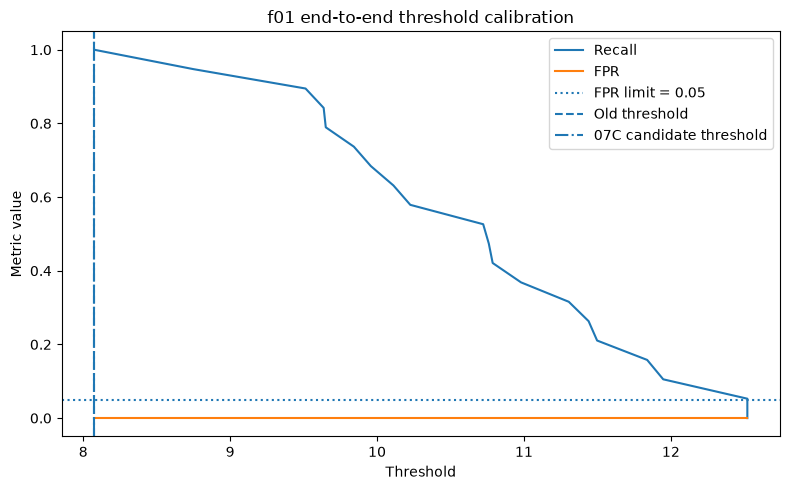

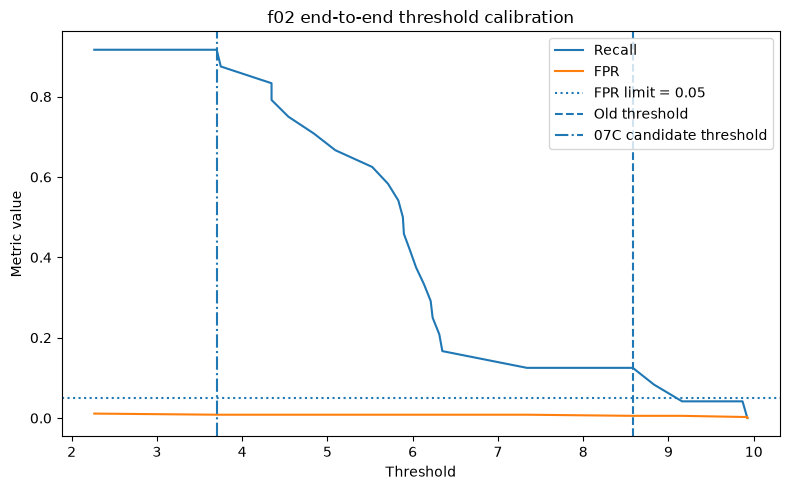

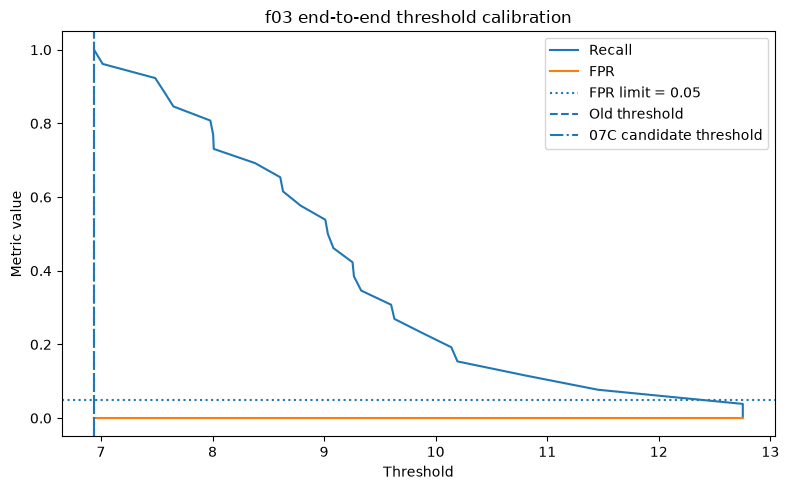

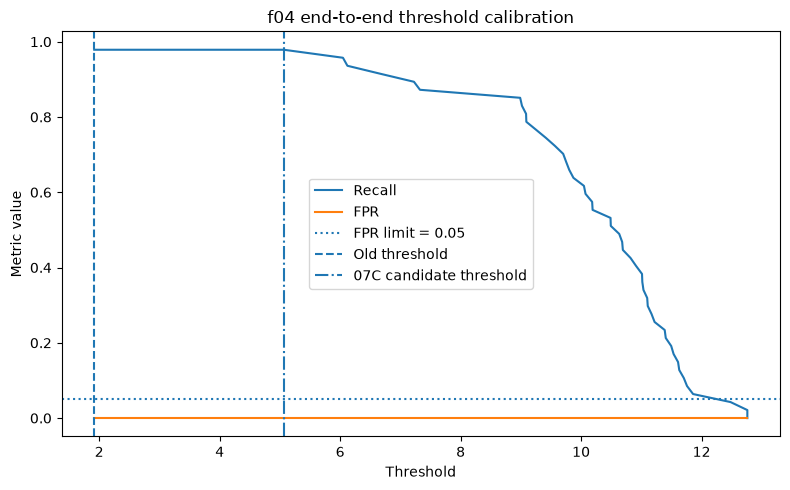

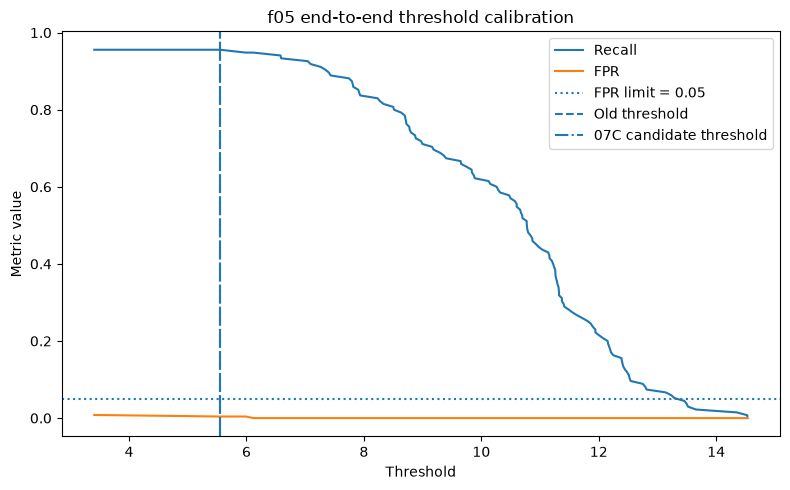

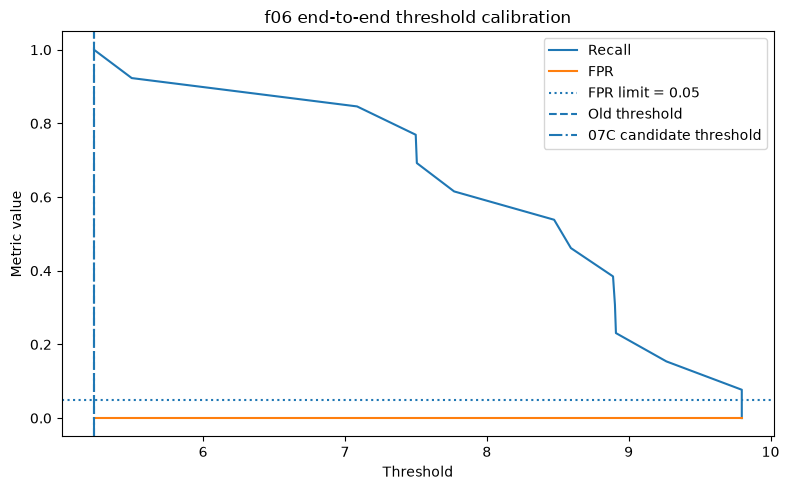

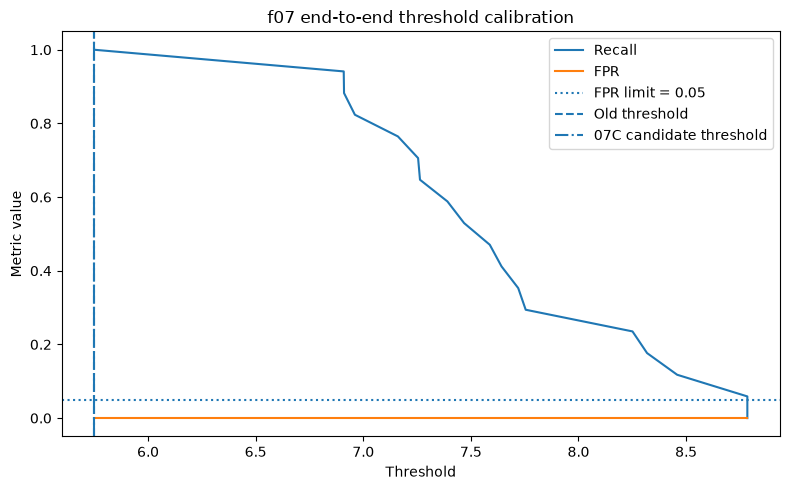

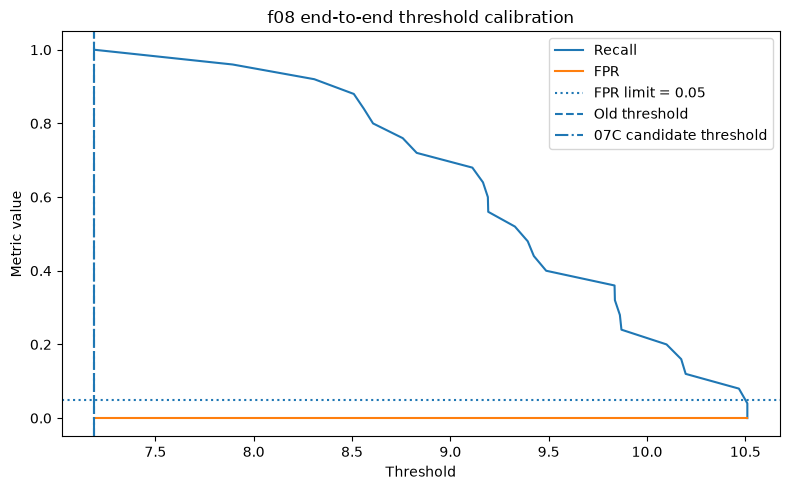

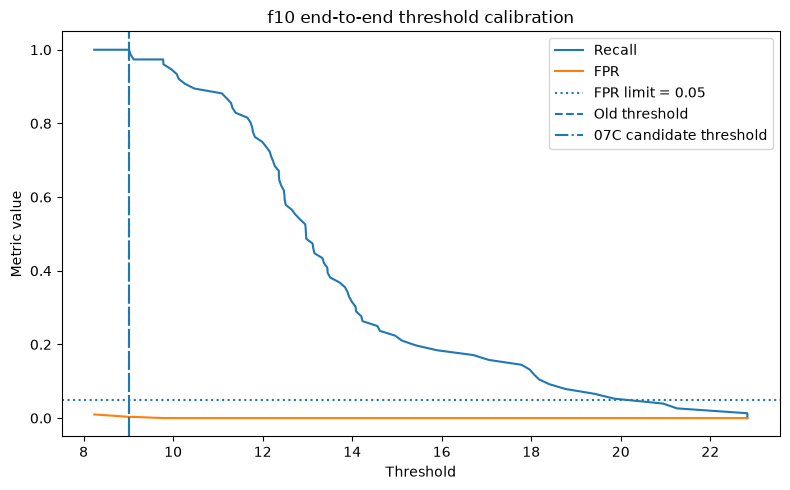

In [13]:
for code in USABLE_CODES:

    subset = (
        threshold_sweep[
            threshold_sweep[
                "code"
            ] == code
        ]
        .sort_values(
            "threshold"
        )
    )

    fig, ax = plt.subplots(
        figsize=(8, 5)
    )

    ax.plot(
        subset[
            "threshold"
        ],
        subset[
            "recall"
        ],
        label="Recall",
    )

    ax.plot(
        subset[
            "threshold"
        ],
        subset[
            "FPR"
        ],
        label="FPR",
    )

    ax.axhline(
        TARGET_MAX_FPR,
        linestyle=":",
        label=f"FPR limit = {TARGET_MAX_FPR:.2f}",
    )

    ax.axvline(
        float(
            OLD_THRESHOLDS[
                code
            ]
        ),
        linestyle="--",
        label="Old threshold",
    )

    ax.axvline(
        float(
            NEW_THRESHOLDS[
                code
            ]
        ),
        linestyle="-.",
        label="07C candidate threshold",
    )

    ax.set(
        title=f"{code} end-to-end threshold calibration",
        xlabel="Threshold",
        ylabel="Metric value",
    )

    ax.legend()

    plt.tight_layout()
    plt.show()

## 12. Sanity checks before saving candidate thresholds

The corrected thresholds are acceptable for review only if:

- all classes are present;
- all selected per-species calibration FPR values satisfy the constraint;
- no GMM or score has changed;
- the raw winning hypothesis column remains exactly the same;
- only rejection/acceptance decisions differ.

In [14]:
assert set(
    NEW_THRESHOLDS
) == set(
    USABLE_CODES
)

assert (
    new_threshold_table[
        "FPR"
    ]
    <= TARGET_MAX_FPR
    + 1e-12
).all()

assert np.array_equal(
    old_detector[
        "hypothesis"
    ].to_numpy(),
    new_detector[
        "hypothesis"
    ].to_numpy(),
)

assert np.array_equal(
    old_detector[
        "true_code"
    ].to_numpy(),
    new_detector[
        "true_code"
    ].to_numpy(),
)

print("Threshold classes       : OK")
print("Per-species FPR limits  : OK")
print("Winning GMM hypotheses  : unchanged")
print("True labels              : unchanged")
print("Only threshold decisions : recalibrated")

Threshold classes       : OK
Per-species FPR limits  : OK
Winning GMM hypotheses  : unchanged
True labels              : unchanged
Only threshold decisions : recalibrated


## 13. Save candidate threshold calibration

The output is intentionally separate from the frozen detector directory.

Nothing in `models/gmm_robust_final/` is overwritten.

In [15]:
threshold_sweep.to_csv(
    RESULTS_DIR
    / "end_to_end_threshold_sweep.csv",
    index=False,
)

new_threshold_table.to_csv(
    RESULTS_DIR
    / "candidate_thresholds_and_metrics.csv",
    index=False,
)

comparison.to_csv(
    RESULTS_DIR
    / "old_vs_candidate_thresholds.csv",
    index=False,
)

old_detector.to_csv(
    RESULTS_DIR
    / "old_detector_decisions.csv",
    index=False,
)

new_detector.to_csv(
    RESULTS_DIR
    / "candidate_detector_decisions.csv",
    index=False,
)

old_species_metrics.to_csv(
    RESULTS_DIR
    / "old_metrics_by_species.csv",
    index=False,
)

new_species_metrics.to_csv(
    RESULTS_DIR
    / "candidate_metrics_by_species.csv",
    index=False,
)

macro_comparison.to_csv(
    RESULTS_DIR
    / "macro_before_after.csv",
    index=False,
)

per_species_before_after.to_csv(
    RESULTS_DIR
    / "per_species_before_after.csv",
    index=False,
)

with open(
    RESULTS_DIR
    / "candidate_thresholds.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        NEW_THRESHOLDS,
        f,
        indent=2,
    )

candidate_metadata = {
    "status":
        "candidate_not_promoted",
    "source_detector_directory":
        str(
            MODEL_DIR
        ),
    "feature":
        FEATURE_NAME,
    "n_components":
        N_COMPONENTS,
    "classes":
        list(
            USABLE_CODES
        ),
    "threshold_selection":
        (
            "end-to-end: hypothesis==class AND LLR_class>=threshold; "
            "maximize recall with FPR<=0.05; larger threshold breaks ties"
        ),
    "gmm_retrained":
        False,
    "scores_recomputed":
        False,
    "train_calibration_split_changed":
        False,
    "old_threshold_file_overwritten":
        False,
    "review_required_before_promotion":
        True,
}

with open(
    RESULTS_DIR
    / "candidate_metadata.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        candidate_metadata,
        f,
        indent=2,
    )

print("Candidate outputs saved to:", RESULTS_DIR)

for path in sorted(
    RESULTS_DIR.iterdir()
):
    print(
        f"  {path.name:<42} "
        f"{path.stat().st_size / 1e6:>8.3f} MB"
    )

print()
print(
    "Frozen thresholds remain unchanged at:",
    OLD_THRESHOLDS_JSON_PATH,
)

Candidate outputs saved to: C:\Users\sofia\Projects\PUCE\frog-presence-replication\data\processed\final_detector_calibration\end_to_end_threshold_calibration
  candidate_detector_decisions.csv              0.028 MB
  candidate_metadata.json                       0.001 MB
  candidate_metrics_by_species.csv              0.001 MB
  candidate_thresholds.json                     0.000 MB
  candidate_thresholds_and_metrics.csv          0.001 MB
  end_to_end_threshold_sweep.csv                0.045 MB
  macro_before_after.csv                        0.000 MB
  old_detector_decisions.csv                    0.028 MB
  old_metrics_by_species.csv                    0.001 MB
  old_vs_candidate_thresholds.csv               0.002 MB
  per_species_before_after.csv                  0.001 MB

Frozen thresholds remain unchanged at: C:\Users\sofia\Projects\PUCE\frog-presence-replication\models\gmm_robust_final\thresholds.json


## 14. Review decision

After execution, inspect these four outputs first:

1. `new_threshold_table`
2. `comparison`
3. `macro_comparison`
4. `per_species_before_after`

### Promotion criterion

A candidate threshold set is reasonable to promote if:

- every species respects `FPR <= 5%`;
- the recall improvement is not purchased with an unacceptable precision loss;
- no class exhibits a pathological threshold caused by only one or two calibration calls;
- the result is interpreted as **calibration performance**, not independent test performance.

### Expected f02 behavior

Notebook 07B suggested that `f02` should move from a very conservative threshold near `8.58` toward a
much lower end-to-end operating point, with recall improving sharply while FPR remains below 5%.

The exact value must come from this all-species recalibration rather than being copied manually from the
single-class diagnostic.

## Next action

If the 07C outputs are satisfactory, the next operation is very small:

- promote `candidate_thresholds.json` to the frozen detector;
- update detector metadata to state that thresholds were selected end-to-end;
- keep the old threshold set archived for provenance.

Only after that should we move to candidate-call segmentation and long-recording inference.